# Mission 3 — `ps03_solution.ipynb`: Multi-Head Attention, RoPE & Grouped-Query KV-Cache

**USSE Noosphere // Squadron Lovelace (Group 01) // Sector SEC-03-M45 (Pleiades Open Cluster, 444 ly)**
Conversational AI — Winter Semester 2026/27 · Problem set `ps03` · AURA Subsystem 03 (+7.1% → 21.3%)
**Environment:** Visual Studio Code with Google Antigravity (`agy`), PyTorch, NVIDIA RTX 3070 (8 GB).

This notebook assembles the four station deliverables (ps03 Part 5) by loading the scripts as modules:

| Part | Station | Officer | Module |
| :-- | :-- | :-- | :-- |
| 1 | Systems Architect | Muhammad Ibrahim | `01_MultiHead_Attention_Core.py` |
| 2 | Communications & Protocol Officer | Anas Asif Hussain Shaik | `02_RoPE_Positional_Engine.py` |
| 3 | Data & Payload Specialist | Areej Ilyas | `03_GQA_and_KVCache_Benchmark.py` |
| 4 | Security & Ethics Sentinel | Arun Dev Valavath | `04_Memory_Hierarchy_and_Safety_Audit.md` (evidence computed below) |

## 0. Setup

In [1]:
import importlib.util, pathlib, sys, math, torch

ROOT = pathlib.Path.cwd()
def load(name, file):
    spec = importlib.util.spec_from_file_location(name, ROOT / file)
    mod = importlib.util.module_from_spec(spec); sys.modules[name] = mod; spec.loader.exec_module(mod)
    return mod

mha_core = load("mha_core", "01_MultiHead_Attention_Core.py")
rope = load("rope_engine", "02_RoPE_Positional_Engine.py")
gqa = load("gqa_kvcache", "03_GQA_and_KVCache_Benchmark.py")
device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "|", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")

torch 2.11.0+cu128 | NVIDIA GeForce RTX 3070


## 1. Part 1 — Multi-head self-attention from scratch

$\text{Attention}(Q,K,V) = \text{softmax}(QK^\top/\sqrt{d_k} + M)V$ with learned $W_Q, W_K, W_V, W_O \in \mathbb{R}^{d_{model}\times d_{model}}$, heads split as `(b, N, h, d_k) → (b, h, N, d_k)`, and $M_{ij}=-\infty$ for $j>i$.

In [2]:
torch.manual_seed(2026)
m = mha_core.MultiHeadSelfAttention(d_model=512, num_heads=8)
x = torch.randn(2, 16, 512)
out, w = m(x, causal=True)
print("output", tuple(out.shape), "| weights", tuple(w.shape))
print("weight on future positions:", w[..., torch.triu(torch.ones(16, 16, dtype=torch.bool), 1)].abs().max().item())
print("max |ours - torch fused SDPA|:", (out - mha_core.reference_attention(x, m, True)).abs().max().item())

output (2, 16, 512) | weights (2, 8, 16, 16)
weight on future positions: 0.0
max |ours - torch fused SDPA|: 7.152557373046875e-07


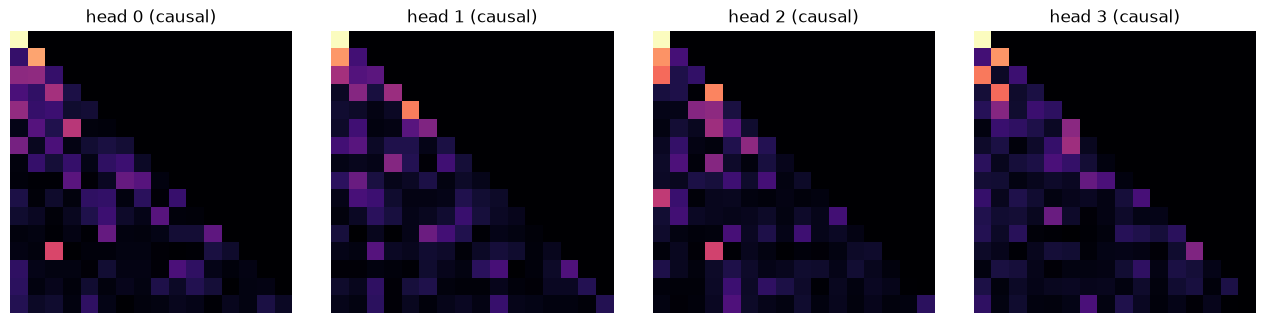

In [3]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 4, figsize=(13, 3.2))
for h in range(4):
    ax[h].imshow(w[0, h].detach(), cmap="magma"); ax[h].set_title(f"head {h} (causal)"); ax[h].axis("off")
plt.tight_layout(); plt.show()

**Variance preservation.** For $q,k\sim\mathcal N(0,I)$: $\mathrm{Var}(q\cdot k)=d_k$; dividing by $\sqrt{d_k}$ restores 1.

In [4]:
for d_k in (16, 64, 128, 256):
    r = mha_core.variance_preservation(d_k)
    print(f"d_k={d_k:>3}: Var(q.k)={r.unscaled_var:7.2f}  Var(q.k/sqrt(d_k))={r.scaled_var:.4f}  "
          f"mean max softmax weight {r.max_softmax_unscaled:.2f} -> {r.max_softmax_scaled:.2f}")

d_k= 16: Var(q.k)=  15.90  Var(q.k/sqrt(d_k))=0.9938  mean max softmax weight 0.60 -> 0.08
d_k= 64: Var(q.k)=  64.08  Var(q.k/sqrt(d_k))=1.0013  mean max softmax weight 0.77 -> 0.07


d_k=128: Var(q.k)= 128.26  Var(q.k/sqrt(d_k))=1.0020  mean max softmax weight 0.85 -> 0.07


d_k=256: Var(q.k)= 256.84  Var(q.k/sqrt(d_k))=1.0033  mean max softmax weight 0.89 -> 0.07


## 2. Part 2 — Rotary positional embeddings

In [5]:
table = rope.precompute_freqs_cis(128, 64)
q = torch.randn(1, 4, 64, 128)
qr = rope.apply_rope(q, table)
print("norm preserved:", torch.allclose(qr.norm(dim=-1), q.norm(dim=-1), atol=1e-4))
res = rope.invariance_trials(trials=500)
print(f"relative invariance over {res['trials']} random (q, k, m, n, delta): max |diff| = {res['max_abs_diff']:.2e}")

norm preserved: True
relative invariance over 500 random (q, k, m, n, delta): max |diff| = 3.97e-06


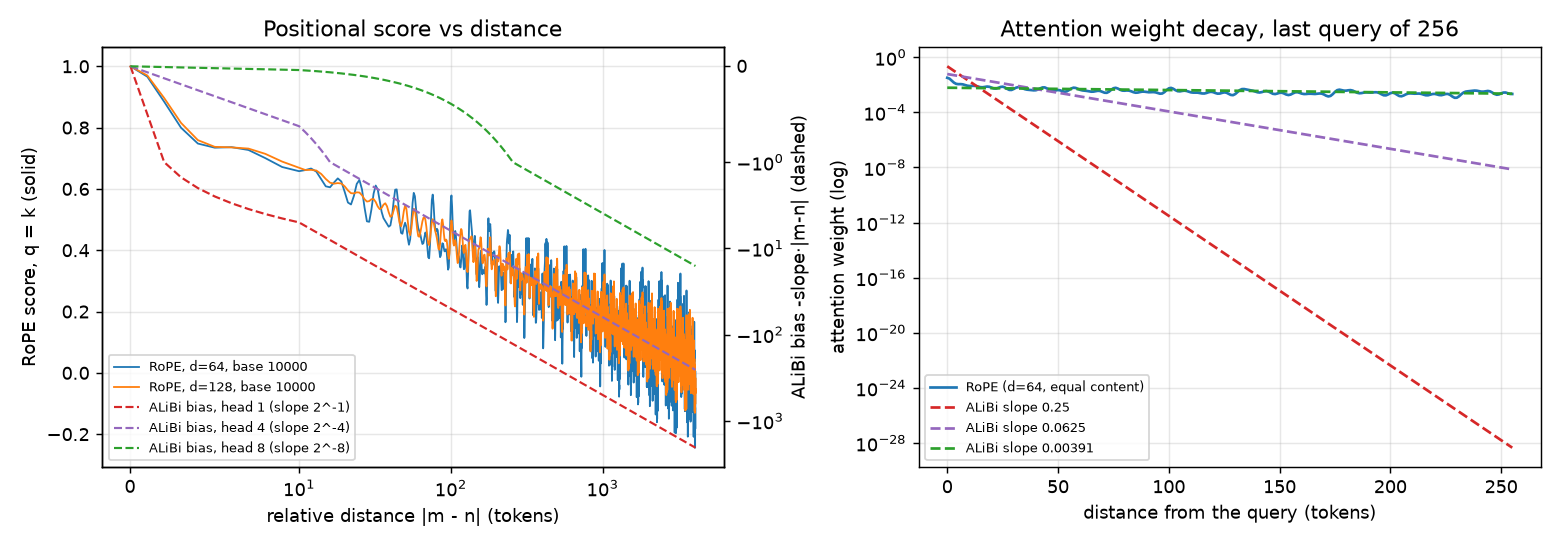

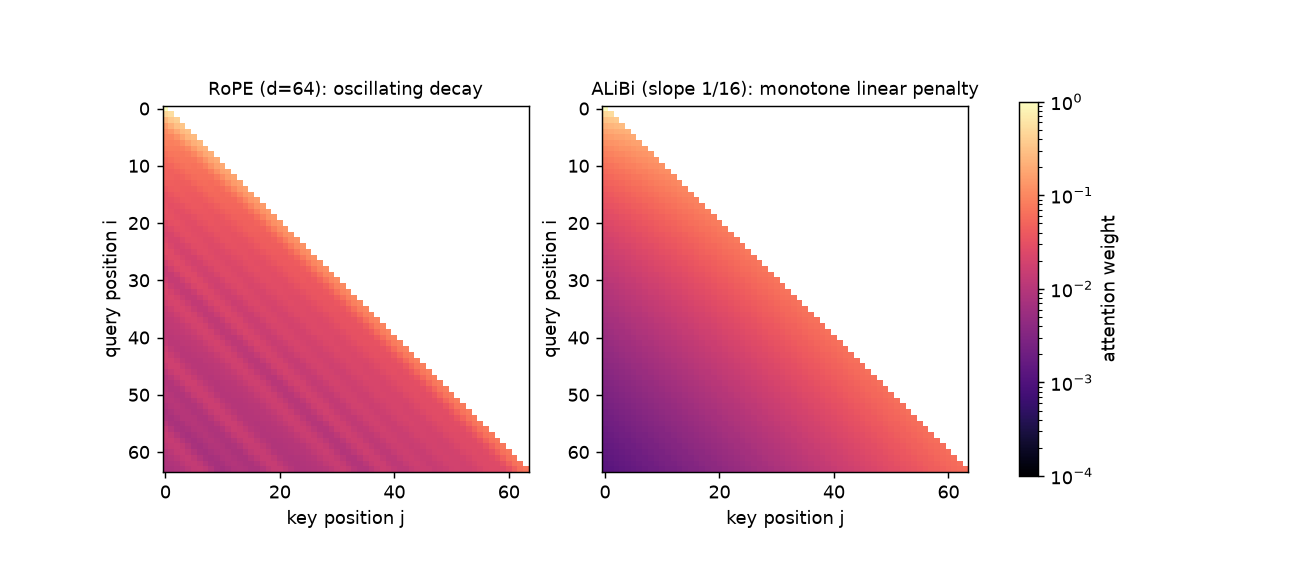

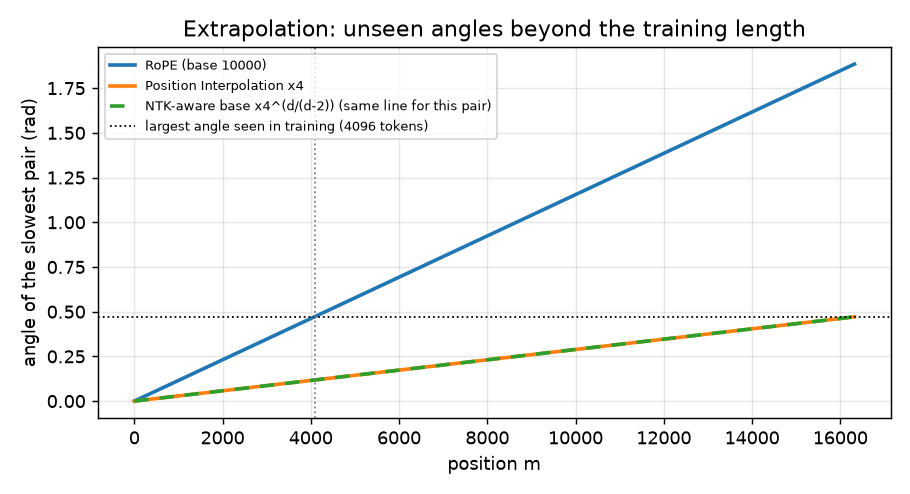

In [6]:
from IPython.display import Image, display
for p in rope.make_figures():
    display(Image(filename=p, width=820))

In [7]:
print(f"{'test length':>11} {'plain RoPE':>11} {'Pos. Interp.':>13} {'NTK base':>9}   share of frequency pairs at unseen angles (trained on 4096)")
for L in (4096, 8192, 16384, 32768):
    f = L / 4096
    print(f"{L:>11,} {rope.unseen_angle_fraction(128, 4096, L):>11.1%} {rope.unseen_angle_fraction(128, 4096, L, position_scale=1/f):>13.1%} "
          f"{rope.unseen_angle_fraction(128, 4096, L, base=rope.ntk_base(10000.0, f, 128)):>9.1%}")

test length  plain RoPE  Pos. Interp.  NTK base   share of frequency pairs at unseen angles (trained on 4096)
      4,096        0.0%          0.0%      0.0%
      8,192       28.1%          0.0%     26.6%
     16,384       28.1%          0.0%     26.6%
     32,768       28.1%          0.0%     26.6%


## 3. Part 3 — GQA and the KV-cache

In [8]:
print("incremental decoding == full causal pass, max diff:", gqa.demo_cache_correctness(device))
rows = gqa.run_benchmark(device)
print(f"{'N':>6} | {'variant':<15} | {'KV MB':>8} | {'GB/s @50 tok/s':>14} | {'ms/token measured':>17} | {'bound ms':>8}")
for r in rows:
    meas = '—' if r['latency_ms_measured'] is None else f"{r['latency_ms_measured']:.2f}"
    print(f"{r['N']:>6} | {r['variant']:<15} | {r['kv_mb']:>8,.0f} | {r['bandwidth_gbps_at_50tps']:>14.1f} | {meas:>17} | {r['latency_ms_bound']:>8.2f}")

incremental decoding == full causal pass, max diff: 2.980232238769531e-07


     N | variant         |    KV MB | GB/s @50 tok/s | ms/token measured | bound ms
  1024 | MHA 32:32       |      512 |           25.0 |             13.98 |     1.20
  1024 | GQA 4:1 (32:8)  |      128 |            6.2 |              9.29 |     0.30
  1024 | MQA 32:1        |       16 |            0.8 |              9.13 |     0.04
  4096 | MHA 32:32       |    2,048 |          100.0 |             18.74 |     4.79
  4096 | GQA 4:1 (32:8)  |      512 |           25.0 |             10.37 |     1.20
  4096 | MQA 32:1        |       64 |            3.1 |              8.56 |     0.15
 16384 | MHA 32:32       |    8,192 |          400.0 |             36.43 |    19.17
 16384 | GQA 4:1 (32:8)  |    2,048 |          100.0 |             17.11 |     4.79
 16384 | MQA 32:1        |      256 |           12.5 |              8.81 |     0.60
 32768 | MHA 32:32       |   16,384 |          800.0 |             57.75 |    38.34
 32768 | GQA 4:1 (32:8)  |    4,096 |          200.0 |             26.72 |  

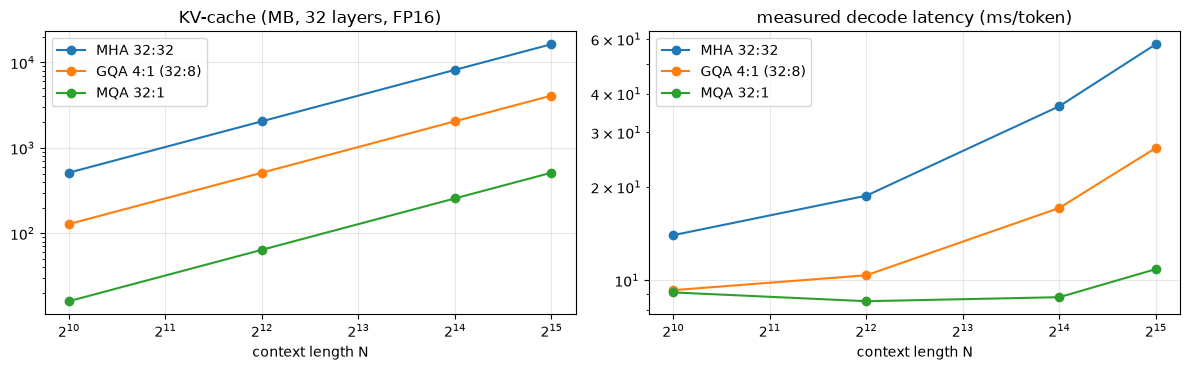

In [9]:
import collections
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
by = collections.defaultdict(list)
for r in rows: by[r['variant']].append(r)
for name, rs in by.items():
    ax[0].plot([r['N'] for r in rs], [r['kv_mb'] for r in rs], marker='o', label=name)
    ax[1].plot([r['N'] for r in rs], [r['latency_ms_measured'] or float('nan') for r in rs], marker='o', label=name)
for a, t in zip(ax, ("KV-cache (MB, 32 layers, FP16)", "measured decode latency (ms/token)")):
    a.set_xscale('log', base=2); a.set_yscale('log'); a.set_xlabel('context length N'); a.set_title(t); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

## 4. Part 4 evidence — FlashAttention IO, KV-cache DoS, PagedAttention, MLA

In [10]:
for N in (512, 1024, 2048, 4096):
    qh, kh, vh = (torch.randn(N, 64, device=device) for _ in range(3))
    io = mha_core.IOCount()
    o = mha_core.flash_attention_tiled(qh, kh, vh, 128, 128, io=io)
    std = mha_core.standard_attention_io(N, 64)
    print(f"N={N:>5}: exact (max diff {(o - mha_core.scaled_dot_product_attention(qh, kh, vh)[0]).abs().max().item():.1e}), "
          f"HBM elements {std.total:,} -> {io.total:,} ({std.total / io.total:.1f}x less)")

N=  512: exact (max diff 1.6e-07), HBM elements 1,179,648 -> 327,680 (3.6x less)
N= 1024: exact (max diff 2.1e-07), HBM elements 4,456,448 -> 1,179,648 (3.8x less)
N= 2048: exact (max diff 2.7e-07), HBM elements 17,301,504 -> 4,456,448 (3.9x less)


N= 4096: exact (max diff 2.5e-07), HBM elements 68,157,440 -> 17,301,504 (3.9x less)


In [11]:
for r in gqa.kv_dos_analytic():
    print(f"{r['variant']:<26} {r['per_session_gb']:6.2f} GB per 65,536-token session -> OOM after {r['max_sessions']} sessions (64 GB free)")
pg = gqa.paged_vs_contiguous()
print(f"contiguous: {pg['contiguous_admitted']} requests, {pg['contiguous_waste']:.1%} wasted | paged: {pg['paged_admitted']} requests, {pg['paged_waste']:.1%} wasted")
for k, v in gqa.kv_bytes_per_token().items():
    print(f"{k:<28} {v/1024:7.1f} KiB/token")

MHA 32:32                   32.00 GB per 65,536-token session -> OOM after 2 sessions (64 GB free)
GQA 4:1 (32:8)               8.00 GB per 65,536-token session -> OOM after 8 sessions (64 GB free)
MQA 32:1                     1.00 GB per 65,536-token session -> OOM after 64 sessions (64 GB free)
MLA (DeepSeek-V3 latent)     2.25 GB per 65,536-token session -> OOM after 28 sessions (64 GB free)
contiguous: 16 requests, 93.6% wasted | paged: 288 requests, 0.4% wasted
MHA (32 KV heads)              512.0 KiB/token
GQA 4:1 (8 KV heads)           128.0 KiB/token
MQA (1 KV head)                 16.0 KiB/token
MLA (d_c = 512 + 64 RoPE)       36.0 KiB/token


## 5. Self-tests

The suite the AI Judge runs (`python -m pytest`).

In [12]:
import subprocess
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider"], cwd=ROOT, capture_output=True, text=True)
print(r.stdout.strip().splitlines()[-1])

26 passed in 5.30s


## Flight sign-off

```
[X] Systems Architect (Muhammad Ibrahim): MultiHeadSelfAttention, causal mask & variance test verified
[X] Communications & Protocol Officer (Anas Asif Hussain Shaik): apply_rope, invariance & decay plots verified
[X] Data & Payload Specialist (Areej Ilyas): GQAAttention, KVCache & VRAM/latency benchmark verified
[X] Security & Ethics Sentinel (Arun Dev Valavath): FlashAttention IO derivation & KV-cache DoS audit verified
```